# ISL Sign Language Recognition — CNN-LSTM vs Transformer
### Training notebook — run this on Google Colab (GPU enabled)

**Before you run this top to bottom:**
1. Turn on GPU: Runtime → Change runtime type → T4 GPU
2. Run **Step 0** — it mounts your Google Drive. Approve the permission popup.
3. Upload your dataset into the Drive folder printed by Step 0 (or pull it in via the Kaggle API — see the commented cell in Step 0).
4. Run **Step 1** and read its output carefully — you MUST edit the `DATA_DIR` / loader logic there to match your actual dataset's file structure. I can't know that in advance, so that cell is deliberately built to help you inspect it first.

Everything this notebook trains gets saved straight to **Google Drive**, not Colab's local disk — that's what fixes the "redo everything at the last minute" problem. It survives runtime disconnects and is there next time you open the notebook.


In [ ]:
# ===== Step 0: Setup & config =====
from google.colab import drive
drive.mount('/content/drive')

import os, json, pickle, random
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ---- EDIT THESE ----
PROJECT_DIR = "/content/drive/MyDrive/ISL_project"      # everything lives under this one Drive folder
DATA_DIR    = os.path.join(PROJECT_DIR, "dataset", "keypoints")       # TODO: upload your dataset here, adjust after Step 1 inspection
OUTPUT_DIR  = os.path.join(PROJECT_DIR, "outputs")       # trained models + artifacts get saved here
NUM_CLASSES = 8         # how many signs you're classifying (keep it small for a 1-week timeline)
SEQ_LEN     = 45          # frames per sequence after padding/truncating

os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))
print("Project folder ready at:", PROJECT_DIR)
print("-> Upload your dataset into:", DATA_DIR)

# ---- OPTIONAL: pull a dataset straight from Kaggle into Drive instead of uploading manually ----
# 1) Get your kaggle.json API token from kaggle.com -> Account -> Create New API Token
# 2) Upload kaggle.json to Colab's file panel (left sidebar), then run:
#
# !pip install -q kaggle
# !mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
# !kaggle datasets download -d <owner>/<dataset-name> -p {DATA_DIR} --unzip


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Project folder ready at: /content/drive/MyDrive/ISL_project
-> Upload your dataset into: /content/drive/MyDrive/ISL_project/dataset/keypoints


In [ ]:
import zipfile
with zipfile.ZipFile('/content/drive/MyDrive/ISL_project/dataset/A Video Dataset of the Hand Gestures of Indian Sign Language Words used in Emergency Situations.zip', 'r') as z:
    z.extractall('/content/drive/MyDrive/ISL_project/dataset')

In [ ]:
import os
extracted_path = "/content/drive/MyDrive/ISL_project/dataset"
for item in os.listdir(extracted_path):
    print(item)

In [ ]:
inner_path = "/content/drive/MyDrive/ISL_project/dataset/A Video Dataset of the Hand Gestures of Indian Sign Language Words used in Emergency Situations"
for item in os.listdir(inner_path):
    print(item)

In [ ]:
cropped_path = inner_path + "/Cropped_Data"
for item in os.listdir(cropped_path):
    print(item)

In [ ]:
import zipfile

organized_path = "/content/drive/MyDrive/ISL_project/dataset/organized_videos"
os.makedirs(organized_path, exist_ok=True)

for zip_name in os.listdir(cropped_path):
    if not zip_name.endswith(".zip"):
        continue
    class_name = zip_name.replace("_Cropped.zip", "")  # e.g. "accident"
    class_out_dir = os.path.join(organized_path, class_name)
    os.makedirs(class_out_dir, exist_ok=True)

    zip_path = os.path.join(cropped_path, zip_name)
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(class_out_dir)
    print(f"Extracted {class_name}")

print("\nDone. Folders created:")
for item in os.listdir(organized_path):
    print(" -", item)

In [ ]:
sample_class = os.listdir(organized_path)[0]
sample_dir = os.path.join(organized_path, sample_class)
print(f"Contents of {sample_class}:")
for f in os.listdir(sample_dir)[:5]:
    print(" -", f)

In [ ]:
nested_dir = os.path.join(sample_dir, "accident_Cropped")
print(f"Contents of {nested_dir}:")
for f in os.listdir(nested_dir)[:10]:
    print(" -", f)

In [ ]:
!pip install -q mediapipe

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 MB 32.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 14.6 MB/s eta 0:00:00


In [ ]:
!wget -q https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task -O hand_landmarker.task

In [ ]:
# ===== Install mediapipe and download the hand landmark model =====

import os, cv2, numpy as np
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

ORGANIZED_DIR = "/content/drive/MyDrive/ISL_project/dataset/organized_videos"
KEYPOINTS_DIR = "/content/drive/MyDrive/ISL_project/dataset/keypoints"
os.makedirs(KEYPOINTS_DIR, exist_ok=True)

base_options = mp_python.BaseOptions(model_asset_path='hand_landmarker.task')
options = vision.HandLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.VIDEO,
    num_hands=2,
    min_hand_detection_confidence=0.5,
)

def extract_landmarks_from_video(video_path, options):
    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    sequence = []
    frame_idx = 0

    with vision.HandLandmarker.create_from_options(options) as landmarker:  # fresh landmarker per video
        while cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                break
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_rgb)
            timestamp_ms = int((frame_idx / fps) * 1000)
            result = landmarker.detect_for_video(mp_image, timestamp_ms)

            frame_landmarks = np.zeros(21 * 3 * 2)  # 21 points x (x,y,z) x 2 hands
            if result.hand_landmarks:
                for i, hand in enumerate(result.hand_landmarks[:2]):
                    coords = np.array([[lm.x, lm.y, lm.z] for lm in hand]).flatten()
                    frame_landmarks[i*63:(i+1)*63] = coords
            sequence.append(frame_landmarks)
            frame_idx += 1

    cap.release()
    return np.array(sequence, dtype=np.float32)

for class_name in sorted(os.listdir(ORGANIZED_DIR)):
    class_dir = os.path.join(ORGANIZED_DIR, class_name)
    if not os.path.isdir(class_dir):
        continue

    # handle the extra "<class>_Cropped" nested folder
    nested = os.path.join(class_dir, f"{class_name}_Cropped")
    video_source_dir = nested if os.path.isdir(nested) else class_dir

    out_class_dir = os.path.join(KEYPOINTS_DIR, class_name)
    os.makedirs(out_class_dir, exist_ok=True)

    video_files = [f for f in os.listdir(video_source_dir) if f.lower().endswith((".avi", ".mp4", ".mov"))]
    for vid_file in video_files:
        vid_path = os.path.join(video_source_dir, vid_file)
        seq = extract_landmarks_from_video(vid_path, options)
        out_path = os.path.join(out_class_dir, vid_file.rsplit(".", 1)[0] + ".npy")
        np.save(out_path, seq)

    print(f"Done: {class_name} ({len(video_files)} videos)")

print("\nAll videos converted to keypoints at:", KEYPOINTS_DIR)

Done: accident (52 videos)
Done: call (52 videos)
Done: doctor (52 videos)
Done: help (52 videos)


## Step 1: Load & inspect the dataset

Datasets that provide MediaPipe keypoints usually come in one of these shapes — **run the inspection code below, look at the printed output, then keep only the branch that matches what you actually see** (delete/comment the other one).

- **Pattern A**: one file per video (`.npy` or `.csv`), one folder per class, e.g. `DATA_DIR/hello/vid001.npy`
- **Pattern B**: one big CSV/parquet with columns like `video_id, frame, x0..xN, y0..yN, label`

Print `os.listdir(DATA_DIR)` first — that alone tells you which pattern you have.


In [ ]:
# ===== Step 1: Inspect dataset structure =====
print("Top-level contents of DATA_DIR:")
print(os.listdir(DATA_DIR)[:20])

# If Pattern A (folders per class), this shows you the class folders + a sample file:
for entry in os.listdir(DATA_DIR)[:5]:
    full = os.path.join(DATA_DIR, entry)
    print(entry, "->", "DIR" if os.path.isdir(full) else "FILE")
    if os.path.isdir(full):
        sample_files = os.listdir(full)[:3]
        print("   sample files:", sample_files)


Top-level contents of DATA_DIR:
['accident', 'call', 'doctor', 'help', 'hot', 'lose', 'pain', 'thief']
accident -> DIR
   sample files: ['accident_Crop_001_02.npy', 'accident_Crop_002_01.npy', 'accident_Crop_001_01.npy']
call -> DIR
   sample files: ['call_Crop_001_01.npy', 'call_Crop_001_02.npy', 'call_Crop_002_01.npy']
doctor -> DIR
   sample files: ['doctor_Crop_001_01.npy', 'doctor_Crop_001_02.npy', 'doctor_Crop_002_01.npy']
help -> DIR
   sample files: ['help_Crop_001_01.npy', 'help_Crop_001_02.npy', 'help_Crop_002_01.npy']
hot -> DIR
   sample files: ['hot_Crop_001_01.npy', 'hot_Crop_001_02.npy', 'hot_Crop_002_01.npy']


In [ ]:
# ===== Step 1b: PATTERN A loader — one array file per video, one folder per class =====
# Use this if DATA_DIR/<class_name>/<video_id>.npy (each .npy is shape [frames, num_landmarks*coords])
# DELETE or skip this cell if you're using Pattern B instead.

def load_pattern_a(data_dir, num_classes=None):
    class_names = sorted([d for d in os.listdir(data_dir)
                           if os.path.isdir(os.path.join(data_dir, d))])
    if num_classes:
        class_names = class_names[:num_classes]

    sequences, labels = [], []
    for cls in class_names:
        cls_dir = os.path.join(data_dir, cls)
        for fname in os.listdir(cls_dir):
            fpath = os.path.join(cls_dir, fname)
            if fname.endswith(".npy"):
                arr = np.load(fpath)
            elif fname.endswith(".csv"):
                import pandas as pd
                arr = pd.read_csv(fpath).values
            else:
                continue
            sequences.append(arr.astype(np.float32))
            labels.append(cls)
    return sequences, labels, class_names

sequences, labels, class_names = load_pattern_a(DATA_DIR, NUM_CLASSES)
print(f"Loaded {len(sequences)} sequences across {len(class_names)} classes")
print("Example sequence shape:", sequences[0].shape)




Loaded 412 sequences across 8 classes
Example sequence shape: (66, 126)


In [ ]:
# ===== Step 1c: PATTERN B loader — one big CSV with video_id + landmark columns + label =====
# Use this if you have a single CSV/parquet file with all keypoints in it.
# DELETE or skip this cell if you're using Pattern A instead.

import pandas as pd

def load_pattern_b(csv_path, id_col="video_id", label_col="label", num_classes=None):
    df = pd.read_csv(csv_path)
    if num_classes:
        top_classes = df[label_col].value_counts().index[:num_classes]
        df = df[df[label_col].isin(top_classes)]

    feature_cols = [c for c in df.columns if c not in (id_col, label_col, "frame")]
    sequences, labels, class_names = [], [], sorted(df[label_col].unique().tolist())

    for vid, group in df.groupby(id_col):
        if "frame" in group.columns:
            group = group.sort_values("frame")
        sequences.append(group[feature_cols].values.astype(np.float32))
        labels.append(group[label_col].iloc[0])

    return sequences, labels, class_names

# sequences, labels, class_names = load_pattern_b(os.path.join(DATA_DIR, "your_file.csv"),
#                                                  num_classes=NUM_CLASSES)
# print(f"Loaded {len(sequences)} sequences across {len(class_names)} classes")
# print("Example sequence shape:", sequences[0].shape)


**Sanity check before moving on** — after loading with whichever pattern applies, run:

```python
print(len(sequences), "sequences total")
print("Feature dimension per frame:", sequences[0].shape[1])
print("Classes:", class_names)
```

If `sequences[0].shape[1]` looks huge (like >1000), you probably have raw video pixels, not keypoints — go back and find the landmarks version of the dataset (Step 0 of the earlier plan). Keypoints per frame for MediaPipe Hands (2 hands) + Pose is typically in the 100–225 range depending on which landmarks are included.


## Step 2: Preprocessing — pad/truncate, normalize, split

This turns your variable-length list of sequences into a fixed-size tensor the models can train on.


In [ ]:
# ===== Step 2: Preprocessing =====
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

def pad_or_truncate(seq, seq_len):
    n = seq.shape[0]
    if n >= seq_len:
        # uniform sample seq_len frames across the video
        idx = np.linspace(0, n - 1, seq_len).astype(int)
        return seq[idx]
    else:
        pad = np.zeros((seq_len - n, seq.shape[1]), dtype=np.float32)
        return np.vstack([seq, pad])

def normalize(seq):
    # per-sequence min-max normalization keeps hand position scale-invariant
    mn, mx = seq.min(), seq.max()
    if mx - mn < 1e-6:
        return seq
    return (seq - mn) / (mx - mn)

X = np.stack([normalize(pad_or_truncate(s, SEQ_LEN)) for s in sequences])
le = LabelEncoder()
y = le.fit_transform(labels)

print("X shape:", X.shape, "  y shape:", y.shape)
print("Classes:", list(le.classes_))

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=SEED)

print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)

NUM_FEATURES = X.shape[2]
NUM_CLASSES = len(le.classes_)

# Save the label encoder + config now — the demo notebook needs these later
with open(os.path.join(OUTPUT_DIR, "label_encoder.pkl"), "wb") as f:
    pickle.dump(le, f)
with open(os.path.join(OUTPUT_DIR, "config.json"), "w") as f:
    json.dump({"seq_len": SEQ_LEN, "num_features": NUM_FEATURES,
                "num_classes": NUM_CLASSES}, f)


X shape: (412, 45, 126)   y shape: (412,)
Classes: [np.str_('accident'), np.str_('call'), np.str_('doctor'), np.str_('help'), np.str_('hot'), np.str_('lose'), np.str_('pain'), np.str_('thief')]
Train: (288, 45, 126) Val: (62, 45, 126) Test: (62, 45, 126)


## Step 3: CNN-LSTM model

Conv1D layers slide over the time axis to pick up short motion patterns (like the start of a hand movement), then the BiLSTM learns how those patterns unfold over the whole sign.


In [ ]:
# ===== Step 3: Build CNN-LSTM =====
def build_cnn_lstm(seq_len, num_features, num_classes):
    inputs = keras.Input(shape=(seq_len, num_features))
    x = layers.Conv1D(64, kernel_size=3, padding="same", activation="relu")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Conv1D(128, kernel_size=3, padding="same", activation="relu")(x)
    x = layers.MaxPooling1D(pool_size=2)(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Bidirectional(layers.LSTM(128, return_sequences=True))(x)
    x = layers.Bidirectional(layers.LSTM(64))(x)
    x = layers.Dropout(0.4)(x)

    x = layers.Dense(64, activation="relu")(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="cnn_lstm")
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

cnn_lstm = build_cnn_lstm(SEQ_LEN, NUM_FEATURES, NUM_CLASSES)
cnn_lstm.summary()


Model: "cnn_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 45, 126)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 45, 64)         │        24,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 45, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 45, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 22, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 22, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 22, 256)        │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 485,512 (1.85 MB)

 Trainable params: 485,384 (1.85 MB)

 Non-trainable params: 128 (512.00 B)

In [ ]:
# ===== Step 3b: Train CNN-LSTM =====
cnn_lstm_ckpt = os.path.join(OUTPUT_DIR, "cnn_lstm_best.keras")

callbacks = [
    keras.callbacks.ModelCheckpoint(cnn_lstm_ckpt, save_best_only=True, monitor="val_accuracy"),
    keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True, monitor="val_accuracy"),
    keras.callbacks.ReduceLROnPlateau(patience=5, factor=0.5),
]

history_cnn_lstm = cnn_lstm.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=60,
    batch_size=16,
    callbacks=callbacks,
    verbose=1,
)
print("Best CNN-LSTM checkpoint saved to:", cnn_lstm_ckpt)


## Step 4: Transformer model

Same input, different architecture — self-attention lets every frame directly attend to every other frame, instead of only passing information sequentially like the LSTM does.


In [ ]:
# ===== Step 4: Build Transformer =====
def positional_encoding(seq_len, d_model):
    pos = np.arange(seq_len)[:, np.newaxis]
    i = np.arange(d_model)[np.newaxis, :]
    angle_rates = 1 / np.power(10000, (2 * (i // 2)) / np.float32(d_model))
    angle_rads = pos * angle_rates
    angle_rads[:, 0::2] = np.sin(angle_rads[:, 0::2])
    angle_rads[:, 1::2] = np.cos(angle_rads[:, 1::2])
    return tf.cast(angle_rads[np.newaxis, ...], dtype=tf.float32)

def transformer_encoder(inputs, head_size, num_heads, ff_dim, dropout=0.3):
    x = layers.LayerNormalization(epsilon=1e-6)(inputs)
    x = layers.MultiHeadAttention(key_dim=head_size, num_heads=num_heads, dropout=dropout)(x, x)
    x = layers.Dropout(dropout)(x)
    res = x + inputs

    x = layers.LayerNormalization(epsilon=1e-6)(res)
    x = layers.Dense(ff_dim, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(inputs.shape[-1])(x)
    return x + res

def build_transformer(seq_len, num_features, num_classes,
                       d_model=128, num_heads=4, ff_dim=256, num_blocks=3):
    inputs = keras.Input(shape=(seq_len, num_features))
    x = layers.Dense(d_model)(inputs)           # project raw features to d_model
    x = x + positional_encoding(seq_len, d_model)

    for _ in range(num_blocks):
        x = transformer_encoder(x, head_size=d_model // num_heads,
                                 num_heads=num_heads, ff_dim=ff_dim)

    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation="relu")(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="transformer")
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

transformer = build_transformer(SEQ_LEN, NUM_FEATURES, NUM_CLASSES)
transformer.summary()


Model: "transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 45, 126)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 45, 128)   │     16,256 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 45, 128)   │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 45, 128)   │        256 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 45, 128)   │     66,048 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 45, 128)   │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 45, 128)   │          0 │ dropout_3[0][0],  │
│                     │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 45, 128)   │        256 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 45, 256)   │     33,024 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 45, 256)   │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 45, 128)   │     32,896 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 45, 128)   │          0 │ dense_4[0][0],    │
│                     │                   │            │ add_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 45, 128)   │        256 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 45, 128)   │     66,048 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 45, 128)   │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 45, 128)   │          0 │ dropout_6[0][0],  │
│                     │                   │            │ add_2[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 45, 128)   │        256 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 45, 256)   │     33,024 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 45, 256)   │          0 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 45, 128)   │     32,896 │ dropout_7[0][0] 

 Total params: 422,472 (1.61 MB)

 Trainable params: 422,472 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ===== Step 4b: Train Transformer =====
transformer_ckpt = os.path.join(OUTPUT_DIR, "transformer_best.keras")

callbacks_t = [
    keras.callbacks.ModelCheckpoint(transformer_ckpt, save_best_only=True, monitor="val_accuracy"),
    keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True, monitor="val_accuracy"),
    keras.callbacks.ReduceLROnPlateau(patience=5, factor=0.5),
]

history_transformer = transformer.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=60,
    batch_size=16,
    callbacks=callbacks_t,
    verbose=1,
)
print("Best Transformer checkpoint saved to:", transformer_ckpt)


Epoch 1/60
18/18 ━━━━━━━━━━━━━━━━━━━━ 35s 406ms/step - accuracy: 0.1562 - loss: 2.7500 - val_accuracy: 0.4032 - val_loss: 1.8500 - learning_rate: 0.0010
Epoch 2/60
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.1979 - loss: 2.1448 - val_accuracy: 0.3710 - val_loss: 1.7107 - learning_rate: 0.0010
Epoch 3/60
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.3229 - loss: 1.7941 - val_accuracy: 0.4355 - val_loss: 1.4837 - learning_rate: 0.0010
Epoch 4/60
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4062 - loss: 1.5347 - val_accuracy: 0.4032 - val_loss: 1.2704 - learning_rate: 0.0010
Epoch 5/60
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.5625 - loss: 1.1158 - val_accuracy: 0.4677 - val_loss: 1.2138 - learning_rate: 0.0010
Epoch 6/60
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.6076 - loss: 1.0614 - val_accuracy: 0.6613 - val_loss: 1.0166 - learning_rate: 0.0010
Epoch 7/60
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6632 - loss: 0.8386 - val_a

In [ ]:
# ===== Step 4c: Build Hybrid CNN-Transformer (with attention access for later viz) =====
def build_hybrid_model(seq_len, num_features, num_classes,
                        d_model=128, num_heads=4, ff_dim=256, num_blocks=2):
    inputs = keras.Input(shape=(seq_len, num_features))

    # CNN front-end: extracts local motion patterns before attention sees them
    x = layers.Conv1D(64, 3, padding="same", activation="relu")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Conv1D(d_model, 3, padding="same", activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    x = x + positional_encoding(seq_len, d_model)

    mha_layers, ln_inputs = [], []
    for i in range(num_blocks):
        residual = x
        xn = layers.LayerNormalization(epsilon=1e-6)(x)
        mha = layers.MultiHeadAttention(key_dim=d_model // num_heads, num_heads=num_heads,
                                          dropout=0.3, name=f"hybrid_mha_{i}")
        attn_out = mha(xn, xn)
        mha_layers.append(mha)
        ln_inputs.append(xn)
        x = layers.Dropout(0.3)(attn_out) + residual

        residual2 = x
        xn2 = layers.LayerNormalization(epsilon=1e-6)(x)
        ff = layers.Dense(ff_dim, activation="relu")(xn2)
        ff = layers.Dropout(0.3)(ff)
        ff = layers.Dense(d_model)(ff)
        x = ff + residual2

    pooled = layers.GlobalAveragePooling1D()(x)
    pooled = layers.Dropout(0.4)(pooled)
    pooled = layers.Dense(64, activation="relu")(pooled)
    outputs = layers.Dense(num_classes, activation="softmax")(pooled)

    model = keras.Model(inputs, outputs, name="hybrid_cnn_transformer")
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model, mha_layers, ln_inputs

hybrid_model, hybrid_mha_layers, hybrid_ln_inputs = build_hybrid_model(SEQ_LEN, NUM_FEATURES, NUM_CLASSES)
hybrid_model.summary()

Model: "hybrid_cnn_transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 45, 126)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 45, 64)    │     24,256 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 45, 64)    │        256 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 45, 128)   │     24,704 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_12          │ (None, 45, 128)   │          0 │ conv1d_3[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_7 (Add)         │ (None, 45, 128)   │          0 │ dropout_12[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 45, 128)   │        256 │ add_7[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ hybrid_mha_0        │ (None, 45, 128)   │     66,048 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_14          │ (None, 45, 128)   │          0 │ hybrid_mha_0[0][… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_8 (Add)         │ (None, 45, 128)   │          0 │ dropout_14[0][0], │
│                     │                   │            │ add_7[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 45, 128)   │        256 │ add_8[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 45, 256)   │     33,024 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_15          │ (None, 45, 256)   │          0 │ dense_11[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 45, 128)   │     32,896 │ dropout_15[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_9 (Add)         │ (None, 45, 128)   │          0 │ dense_12[0][0],   │
│                     │                   │            │ add_8[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 45, 128)   │        256 │ add_9[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ hybrid_mha_1        │ (None, 45, 128)   │     66,048 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_17          │ (None, 45, 128)   │          0 │ hybrid_mha_1[0][… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 322,952 (1.23 MB)

 Trainable params: 322,824 (1.23 MB)

 Non-trainable params: 128 (512.00 B)

In [ ]:
# ===== Step 4d: Train Hybrid model =====
hybrid_ckpt = os.path.join(OUTPUT_DIR, "hybrid_best.keras")

callbacks_h = [
    keras.callbacks.ModelCheckpoint(hybrid_ckpt, save_best_only=True, monitor="val_accuracy"),
    keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True, monitor="val_accuracy"),
    keras.callbacks.ReduceLROnPlateau(patience=5, factor=0.5),
]

history_hybrid = hybrid_model.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=60, batch_size=16, callbacks=callbacks_h, verbose=1,
)
print("Best Hybrid checkpoint saved to:", hybrid_ckpt)

Epoch 1/60
18/18 ━━━━━━━━━━━━━━━━━━━━ 27s 361ms/step - accuracy: 0.2986 - loss: 1.9966 - val_accuracy: 0.2097 - val_loss: 2.1560 - learning_rate: 0.0010
Epoch 2/60
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.5451 - loss: 1.2247 - val_accuracy: 0.3065 - val_loss: 2.3820 - learning_rate: 0.0010
Epoch 3/60
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7257 - loss: 0.7437 - val_accuracy: 0.1774 - val_loss: 2.1542 - learning_rate: 0.0010
Epoch 4/60
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.7882 - loss: 0.5435 - val_accuracy: 0.4194 - val_loss: 1.7451 - learning_rate: 0.0010
Epoch 5/60
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.8333 - loss: 0.4178 - val_accuracy: 0.4839 - val_loss: 1.3798 - learning_rate: 0.0010
Epoch 6/60
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8854 - loss: 0.3626 - val_accuracy: 0.4516 - val_loss: 1.4286 - learning_rate: 0.0010
Epoch 7/60
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8507 - loss: 0.3413 - val_a

## Step 5: Evaluate & compare

This is the core result for your report/slides — accuracy plus a side-by-side comparison of the two architectures.



=== CNN-LSTM ===
Test accuracy: 0.1452
              precision    recall  f1-score   support

    accident       0.00      0.00      0.00         8
        call       0.50      0.29      0.36         7
      doctor       0.00      0.00      0.00         8
        help       0.00      0.00      0.00         8
         hot       0.00      0.00      0.00         8
        lose       0.13      0.88      0.22         8
        pain       0.00      0.00      0.00         8
       thief       0.00      0.00      0.00         7

    accuracy                           0.15        62
   macro avg       0.08      0.15      0.07        62
weighted avg       0.07      0.15      0.07        62



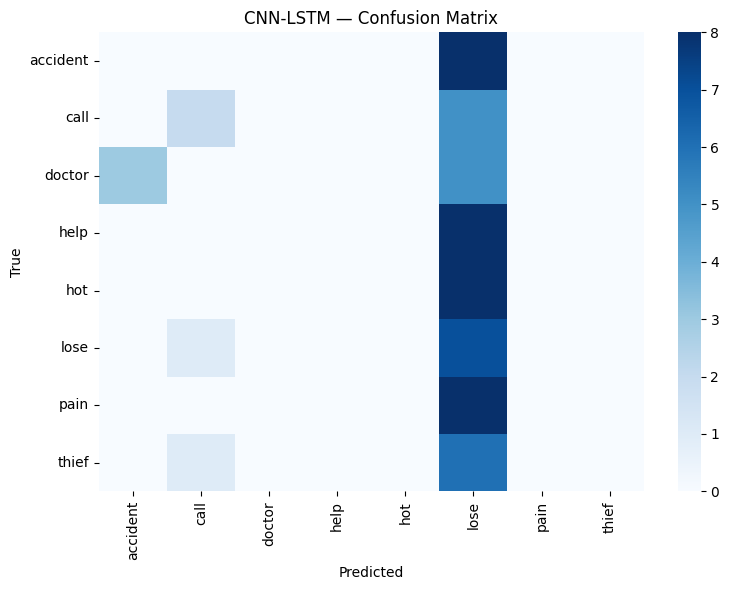


=== Transformer ===
Test accuracy: 0.8871
              precision    recall  f1-score   support

    accident       1.00      1.00      1.00         8
        call       0.50      0.57      0.53         7
      doctor       1.00      0.62      0.77         8
        help       1.00      1.00      1.00         8
         hot       0.89      1.00      0.94         8
        lose       1.00      1.00      1.00         8
        pain       0.88      0.88      0.88         8
       thief       0.88      1.00      0.93         7

    accuracy                           0.89        62
   macro avg       0.89      0.88      0.88        62
weighted avg       0.90      0.89      0.89        62



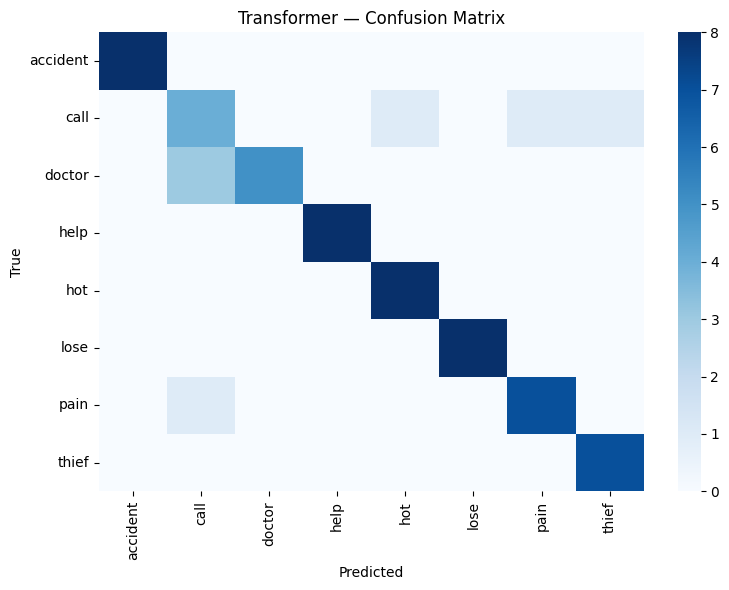

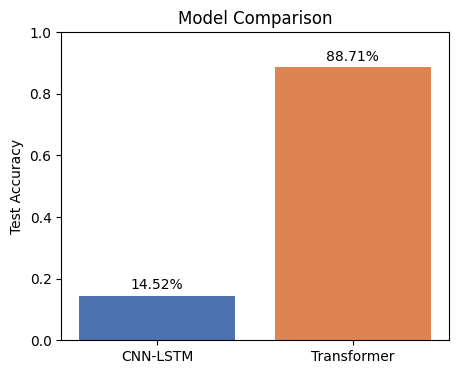


Final comparison — CNN-LSTM: 14.52%   Transformer: 88.71%


In [ ]:
# ===== Step 5: Evaluation =====
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

def evaluate(model, name, X_test, y_test, class_names):
    loss, acc = model.evaluate(X_test, y_test, verbose=0)
    y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
    print(f"\n=== {name} ===")
    print(f"Test accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=False, cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f"{name} — Confusion Matrix")
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.xticks(rotation=90); plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"{name}_confusion_matrix.png"))
    plt.show()
    return acc

class_names = list(le.classes_)
acc_cnn_lstm = evaluate(cnn_lstm, "CNN-LSTM", X_test, y_test, class_names)
acc_transformer = evaluate(transformer, "Transformer", X_test, y_test, class_names)

plt.figure(figsize=(5, 4))
plt.bar(["CNN-LSTM", "Transformer"], [acc_cnn_lstm, acc_transformer], color=["#4C72B0", "#DD8452"])
plt.ylabel("Test Accuracy"); plt.ylim(0, 1)
plt.title("Model Comparison")
for i, v in enumerate([acc_cnn_lstm, acc_transformer]):
    plt.text(i, v + 0.02, f"{v:.2%}", ha="center")
plt.savefig(os.path.join(OUTPUT_DIR, "model_comparison.png"))
plt.show()

print(f"\nFinal comparison — CNN-LSTM: {acc_cnn_lstm:.2%}   Transformer: {acc_transformer:.2%}")



=== Hybrid-CNN-Transformer ===
Test accuracy: 0.9355
              precision    recall  f1-score   support

    accident       1.00      1.00      1.00         8
        call       0.67      0.86      0.75         7
      doctor       1.00      0.62      0.77         8
        help       1.00      1.00      1.00         8
         hot       1.00      1.00      1.00         8
        lose       1.00      1.00      1.00         8
        pain       1.00      1.00      1.00         8
       thief       0.88      1.00      0.93         7

    accuracy                           0.94        62
   macro avg       0.94      0.94      0.93        62
weighted avg       0.95      0.94      0.93        62



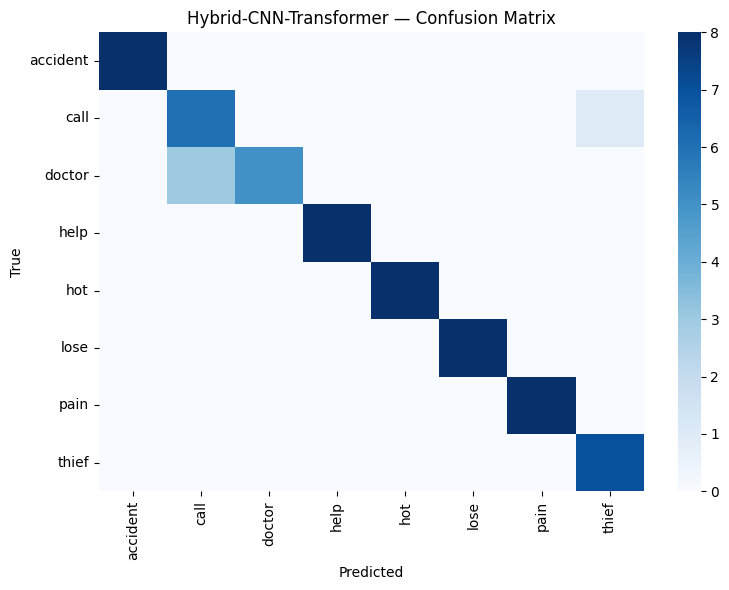

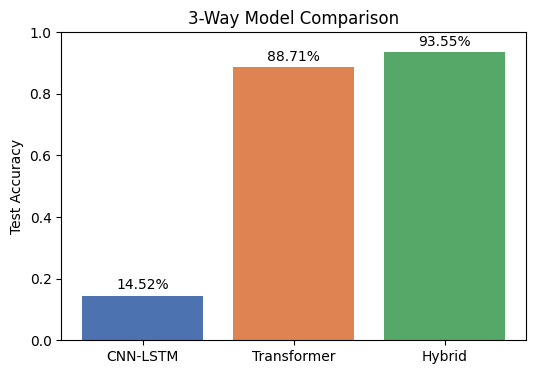

In [ ]:
# ===== Step 5b: Add Hybrid to evaluation + 3-way comparison =====
acc_hybrid = evaluate(hybrid_model, "Hybrid-CNN-Transformer", X_test, y_test, class_names)

plt.figure(figsize=(6, 4))
names = ["CNN-LSTM", "Transformer", "Hybrid"]
accs = [acc_cnn_lstm, acc_transformer, acc_hybrid]
plt.bar(names, accs, color=["#4C72B0", "#DD8452", "#55A868"])
plt.ylabel("Test Accuracy"); plt.ylim(0, 1)
plt.title("3-Way Model Comparison")
for i, v in enumerate(accs):
    plt.text(i, v + 0.02, f"{v:.2%}", ha="center")
plt.savefig(os.path.join(OUTPUT_DIR, "model_comparison_3way.png"))
plt.show()

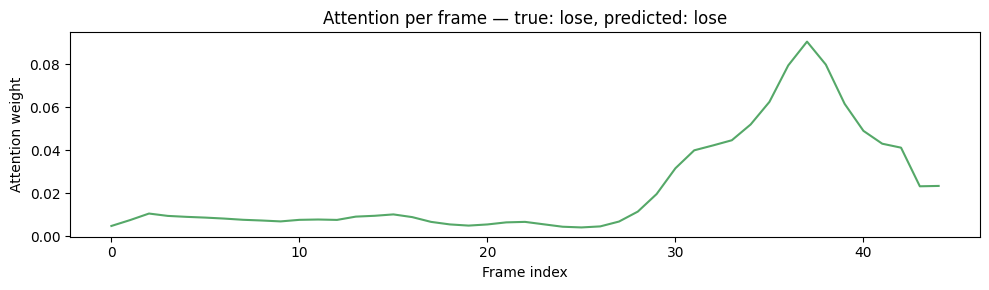

In [ ]:
# ===== Step 5c: Attention visualization — which frames the model focused on =====
last_mha = hybrid_mha_layers[-1]
last_ln_input = hybrid_ln_inputs[-1]
_, attn_scores = last_mha(last_ln_input, last_ln_input, return_attention_scores=True)
attention_probe_model = keras.Model(hybrid_model.input, [hybrid_model.output, attn_scores])

sample_x = X_test[:1]
sample_true_label = class_names[y_test[0]]
preds, attn = attention_probe_model.predict(sample_x, verbose=0)
avg_attn = attn[0].mean(axis=0)          # average across attention heads
frame_importance = avg_attn.mean(axis=0)  # how much attention each frame received overall

plt.figure(figsize=(10, 3))
plt.plot(frame_importance, color="#55A868")
plt.title(f"Attention per frame — true: {sample_true_label}, predicted: {class_names[np.argmax(preds[0])]}")
plt.xlabel("Frame index"); plt.ylabel("Attention weight")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "attention_visualization.png"))
plt.show()

## Step 6: Wrap up

Everything you need for the demo notebook is now in `/kaggle/working/`:
- `cnn_lstm_best.keras`
- `transformer_best.keras`
- `label_encoder.pkl`
- `config.json`
- confusion matrix + comparison PNGs (use these directly in your slides)

All of it is already sitting in **Google Drive** (`{PROJECT_DIR}/outputs`), so there's nothing extra to "save" the way Kaggle needs a version commit — it's just there. Also save this notebook itself to Drive if it isn't already (File → Save a copy in Drive) so the code is preserved alongside the outputs.


In [ ]:
# ===== Step 6: Confirm everything is saved =====
print("Files in OUTPUT_DIR:")
for f in os.listdir(OUTPUT_DIR):
    print(" -", f)


In [ ]:
import os

# Make a clean submission folder
SUBMIT_DIR = "/content/drive/MyDrive/ISL_project/submission"
os.makedirs(SUBMIT_DIR, exist_ok=True)

# Copy the two notebooks in
!cp "/content/drive/MyDrive/ISL_project/ISL_train.ipynb" "{SUBMIT_DIR}/ISL_train.ipynb"
!cp "/content/drive/MyDrive/ISL_project/ISL_demo.ipynb" "{SUBMIT_DIR}/ISL_demo.ipynb"

# Copy the keypoints dataset (NOT the raw 3GB videos)
!cp -r "/content/drive/MyDrive/ISL_project/dataset/keypoints" "{SUBMIT_DIR}/dataset_keypoints"

print("Contents of submission folder:")
for f in os.listdir(SUBMIT_DIR):
    print(" -", f)

Contents of submission folder:
 - dataset_keypoints
 - ISL_train.ipynb
 - ISL_demo.ipynb


In [ ]:
readme_text = """ISL Sign Language Recognition - Project Submission

Contents:
- ISL_train.ipynb  : training notebook (CNN-LSTM, Transformer, Hybrid CNN-Transformer)
- ISL_demo.ipynb   : live inference demo notebook (Gradio dashboard)
- dataset_keypoints/ : MediaPipe-extracted hand-landmark sequences (.npy files),
                       preprocessed from the original video dataset.

Original raw video dataset source:
V. Adithya and R. Rajesh, "Hand gestures for emergency situations: A video dataset
based on words from Indian sign language," Data in Brief, vol. 31, 106016, 2020.
https://data.mendeley.com/datasets/2vfdm42337/1
"""

with open(f"{SUBMIT_DIR}/README.txt", "w") as f:
    f.write(readme_text)
print("README added.")

README added.


In [ ]:
!cd "/content/drive/MyDrive/ISL_project" && zip -r submission.zip submission/
print("Zip created at: /content/drive/MyDrive/ISL_project/submission.zip")

  adding: submission/ (stored 0%)
  adding: submission/dataset_keypoints/ (stored 0%)
  adding: submission/dataset_keypoints/accident/ (stored 0%)
  adding: submission/dataset_keypoints/accident/accident_Crop_001_02.npy (deflated 8%)
  adding: submission/dataset_keypoints/accident/accident_Crop_002_01.npy (deflated 35%)
  adding: submission/dataset_keypoints/accident/accident_Crop_001_01.npy (deflated 8%)
  adding: submission/dataset_keypoints/accident/accident_Crop_002_02.npy (deflated 33%)
  adding: submission/dataset_keypoints/accident/accident_Crop_003_01.npy (deflated 54%)
  adding: submission/dataset_keypoints/accident/accident_Crop_003_02.npy (deflated 55%)
  adding: submission/dataset_keypoints/accident/accident_Crop_004_01.npy (deflated 46%)
  adding: submission/dataset_keypoints/accident/accident_Crop_004_02.npy (deflated 60%)
  adding: submission/dataset_keypoints/accident/accident_Crop_005_01.npy (deflated 26%)
  adding: submission/dataset_keypoints/accident/accident_Crop_0